# CJP Protest Tracker v2
**Research question:** *Where, why and how did students protest exam paper leaks in India, and how did authorities respond?*

This notebook improves my internship pipeline (`CJP_Colab_file.ipynb`) in four steps:
1. **Clean the data**: split headline and outlet, remove HTML leftovers, remove duplicate stories.
2. **Fix the extraction rules**: whole-word matching, then measure *before vs after*.
3. **Train a small ML model** (TF-IDF + Logistic Regression) to label each article's **Event Type**, and compare it with the old keyword rules.
4. **Analyse**: charts and findings.

Input: the 2,072-row spreadsheet produced by the original notebook. The original notebook and spreadsheet are not changed.
No API keys are needed here.

## 0. Setup

In [1]:
import sys, subprocess, re, html, os
from urllib.parse import urlparse

try:
    import rapidfuzz  # used for duplicate detection
except ImportError:  # Colab does not have it installed by default
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz, process

IN_COLAB = "google.colab" in sys.modules

# Find the original spreadsheet (same folder in Colab, parent folder locally)
SPREADSHEET = "CJp_Dataset spreadsheet (1).xlsx"
for candidate in [SPREADSHEET, os.path.join("..", SPREADSHEET)]:
    if os.path.exists(candidate):
        SPREADSHEET_PATH = candidate
        break
else:
    raise FileNotFoundError(f"Upload '{SPREADSHEET}' next to this notebook first.")

os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
pd.set_option("display.max_colwidth", 90)
print("Using:", SPREADSHEET_PATH)

Using: CJp_Dataset spreadsheet (1).xlsx


## 1. Load and clean
The old pipeline stored the headline and the news outlet together in the "Reason" column, e.g.
`NEET paper leak: CBI arrests two&nbsp;&nbsp;India Today`. We split it into **Headline** and **Outlet**.

- Google News rows: headline and outlet are separated by `&nbsp;&nbsp;`.
- GNews / NewsData rows: the headline is rebuilt from the link (e.g. `.../cjp-protest-at-jantar-mantar` → "cjp protest at jantar mantar"),
  the outlet is the website name, and the "Reason" text is the real description.

In [2]:
raw = pd.read_excel(SPREADSHEET_PATH)
print("Rows in original spreadsheet:", len(raw))


def clean_text(text):
    """Turn HTML entities into characters, remove tags and invisible characters, squash spaces."""
    if not isinstance(text, str):
        return ""
    text = html.unescape(html.unescape(text))          # &nbsp; -> space, &amp; -> &
    text = re.sub(r"<.*?>", " ", text)                 # leftover HTML tags
    text = text.replace("​", "").replace("\xa0", " ")
    return re.sub(r"\s+", " ", text).strip()


def headline_from_url(url):
    """Rebuild a readable headline from the URL slug (for non-Google-News rows)."""
    if "news.google.com" in url:            # encoded redirect link: no readable words in it
        return ""
    parts = [p for p in urlparse(url).path.split("/") if p]
    parts = [p for p in parts if p not in ("articleshow", "amp") and not re.fullmatch(r"[\d.]+(cms|html?)?", p)]
    if not parts:
        return ""
    slug = max(parts, key=len)
    slug = re.sub(r"\.(cms|html?|ece|php)$", "", slug)
    slug = re.sub(r"[-_]?\d{6,}$", "", slug)            # trailing article ids
    return slug.replace("-", " ").replace("_", " ").strip()


def split_row(row):
    reason, link = row["Reason"], row["Link"]
    if isinstance(reason, str) and "&nbsp;" in reason:          # Google News RSS format
        headline, _, outlet = reason.partition("&nbsp;&nbsp;")
        headline, outlet = clean_text(headline), clean_text(outlet)
        if outlet and headline.endswith(outlet):                  # "... | Hindustan Times"
            headline = headline[: -len(outlet)].rstrip(" |-–")
        return headline, outlet, ""
    outlet = urlparse(link).netloc.replace("www.", "")
    return clean_text(headline_from_url(link)), outlet, clean_text(reason)


df = raw.copy()
df[["Headline", "Outlet", "Description"]] = df.apply(lambda r: pd.Series(split_row(r)), axis=1)
df["Text"] = (df["Headline"] + ". " + df["Description"]).str.strip(" .")
df["Published Date"] = pd.to_datetime(df["Published Date"], errors="coerce")
df[["Headline", "Outlet", "Description"]].head(8)

Rows in original spreadsheet: 2072


,Headline,Outlet,Description
0,CJP's Saurav Das Hails Supreme Court Clarification on Student Protest FIRs,NDTV,
1,CJP Movement: How Gen Z's Protests Are Reshaping India's Political Landscape,Daily Pioneer,
2,SOG arrests AE in 2020 Junior Engineer paper leak case Rajasthan,Daily Pioneer,
3,Prashant Kishor on Bankipur win: CJP stir may have helped,Rediff,
4,Jharkhand student leader begins hunger strike as CJP lends support to protest,Rediff,
5,Centre to Explain NEET Paper Chain to SC,Kashmir Observer,
6,"Don't look at Bangladesh or Nepal, follow Gandhi: CJP chief Abhijeet Dipke",India Today,
7,Viral video shows Delhi Police urging CJP organisers to make crowd-control arrangements,Rediff,


## 2. The old rules vs the fixed rules
**The bug:** the old code checked `if "CAT" in text`, which is also true for "edu**CAT**ion" or "**CAT**ch-up".
That is a *substring* match. The fix is a *whole-word* match with the regex word boundary `\b`.

Other fixes:
- **Longest name first**, so "NEET PG" is checked before "NEET".
- **Short aliases**: "JEE", "SSC", "NEET-UG", "UGC-NET".
- **Ambiguous short names** (NDA = also the political alliance, CAT/MAT/GATE = ordinary words, CDS, IFS, AIIMS = a hospital)
  only count when followed by *exam / paper / result / admit / a year*.
- **Cities → states** (Patna → Bihar, Jantar Mantar → Delhi …), so fewer states are "Unknown".
- **Exam Year** only when the headline mentions a year. The old code guessed it from the publish date.

In [3]:
# Lookup tables copied from the original notebook (cell 10)
EXAM_DATABASE = {
    "UPSC": ("UPSC Civil Services Examination", "Government", "UPSC", "Union Public Service Commission", "PBT + Interview"),
    "IFS": ("Indian Forest Service", "Government", "UPSC", "Union Public Service Commission", "PBT"),
    "CDS": ("Combined Defence Services", "Defence", "UPSC", "Union Public Service Commission", "PBT"),
    "NDA": ("National Defence Academy", "Defence", "UPSC", "Union Public Service Commission", "PBT"),
    "CAPF": ("Central Armed Police Forces", "Defence", "UPSC", "Union Public Service Commission", "PBT"),
    "SSC CGL": ("SSC Combined Graduate Level", "Government", "SSC", "Staff Selection Commission", "CBT"),
    "SSC CHSL": ("SSC CHSL", "Government", "SSC", "Staff Selection Commission", "CBT"),
    "SSC GD": ("SSC GD Constable", "Defence", "SSC", "Staff Selection Commission", "CBT"),
    "SSC MTS": ("SSC MTS", "Government", "SSC", "Staff Selection Commission", "CBT"),
    "SSC CPO": ("SSC CPO", "Police", "SSC", "Staff Selection Commission", "CBT"),
    "SSC JE": ("SSC Junior Engineer", "Engineering", "SSC", "Staff Selection Commission", "CBT"),
    "IBPS PO": ("IBPS Probationary Officer", "Banking", "IBPS", "Institute of Banking Personnel Selection", "CBT"),
    "IBPS CLERK": ("IBPS Clerk", "Banking", "IBPS", "Institute of Banking Personnel Selection", "CBT"),
    "IBPS RRB": ("IBPS RRB", "Banking", "IBPS", "Institute of Banking Personnel Selection", "CBT"),
    "SBI PO": ("SBI Probationary Officer", "Banking", "SBI", "State Bank of India", "CBT"),
    "SBI CLERK": ("SBI Clerk", "Banking", "SBI", "State Bank of India", "CBT"),
    "RBI GRADE B": ("RBI Grade B", "Banking", "RBI", "Reserve Bank of India", "CBT"),
    "JEE MAIN": ("JEE Main", "Engineering", "NTA", "National Testing Agency", "CBT"),
    "JEE ADVANCED": ("JEE Advanced", "Engineering", "IIT", "IIT", "CBT"),
    "GATE": ("Graduate Aptitude Test in Engineering", "Engineering", "IIT", "IISc/IITs", "CBT"),
    "NEET": ("NEET UG", "Medical", "NTA", "National Testing Agency", "PBT"),
    "NEET PG": ("NEET PG", "Medical", "NBEMS", "National Board of Examinations", "CBT"),
    "AIIMS": ("AIIMS Entrance", "Medical", "AIIMS", "AIIMS", "CBT"),
    "CLAT": ("Common Law Admission Test", "Law", "Consortium of NLUs", "Consortium of National Law Universities", "PBT"),
    "AILET": ("AILET", "Law", "NLU Delhi", "National Law University Delhi", "PBT"),
    "CAT": ("Common Admission Test", "MBA", "IIM", "Indian Institutes of Management", "CBT"),
    "XAT": ("Xavier Aptitude Test", "MBA", "XLRI", "XLRI", "CBT"),
    "CMAT": ("CMAT", "MBA", "NTA", "National Testing Agency", "CBT"),
    "MAT": ("Management Aptitude Test", "MBA", "AIMA", "All India Management Association", "PBT/CBT"),
    "RRB NTPC": ("RRB NTPC", "Railway", "RRB", "Railway Recruitment Board", "CBT"),
    "RRB GROUP D": ("RRB Group D", "Railway", "RRB", "Railway Recruitment Board", "CBT"),
    "RRB ALP": ("Assistant Loco Pilot", "Railway", "RRB", "Railway Recruitment Board", "CBT"),
    "CTET": ("Central Teacher Eligibility Test", "Teaching", "CBSE", "CBSE", "CBT"),
    "UGC NET": ("UGC NET", "Teaching", "NTA", "National Testing Agency", "CBT"),
    "AFCAT": ("Air Force Common Admission Test", "Defence", "Indian Air Force", "Indian Air Force", "CBT"),
    "AGNIVEER": ("Agniveer Recruitment", "Defence", "Indian Armed Forces", "Indian Army/Navy/Air Force", "CBT"),
    "BPSC": ("Bihar Public Service Commission", "Government", "BPSC", "BPSC", "PBT"),
    "UPPSC": ("Uttar Pradesh Public Service Commission", "Government", "UPPSC", "UPPSC", "PBT"),
    "MPPSC": ("Madhya Pradesh Public Service Commission", "Government", "MPPSC", "MPPSC", "PBT"),
    "APPSC": ("Andhra Pradesh Public Service Commission", "Government", "APPSC", "APPSC", "PBT"),
    "TNPSC": ("Tamil Nadu Public Service Commission", "Government", "TNPSC", "TNPSC", "PBT"),
}
EXAM_FIELDS = ["Name of Exam", "Exam Category", "Board", "Conducted By", "PBT/CBT"]
UNKNOWN_EXAM = dict.fromkeys(EXAM_FIELDS, "Unknown")

INDIAN_STATES = [
    "Andhra Pradesh", "Arunachal Pradesh", "Assam", "Bihar", "Chhattisgarh", "Goa", "Gujarat", "Haryana",
    "Himachal Pradesh", "Jharkhand", "Karnataka", "Kerala", "Madhya Pradesh", "Maharashtra", "Manipur",
    "Meghalaya", "Mizoram", "Nagaland", "Odisha", "Punjab", "Rajasthan", "Sikkim", "Tamil Nadu", "Telangana",
    "Tripura", "Uttar Pradesh", "Uttarakhand", "West Bengal", "Delhi", "Jammu and Kashmir", "Ladakh",
    "Chandigarh", "Puducherry", "Andaman and Nicobar Islands", "Dadra and Nagar Haveli and Daman and Diu", "Lakshadweep",
]

CATEGORY_KEYWORDS = {  # copied from the original notebook (cell 3); order matters for the old rules
    "Paper Leak": ["paper leak", "question paper", "question leak", "exam leak", "leaked paper", "answer key leak", "question paper leaked"],
    "Investigation": ["investigation", "probe", "CBI", "SIT", "FIR", "arrest", "custody"],
    "Exam": ["NEET", "JEE", "CUET", "UPSC", "SSC", "UGC NET", "CTET", "BPSC", "UPPSC", "RPSC", "HPSC", "competitive exam", "recruitment exam"],
    "Court": ["Supreme Court", "High Court", "petition", "hearing", "judgment", "verdict"],
    "CJP": ["CJP", "CJP case", "CJP investigation", "CJP scam"],
}


# ---------- OLD rules (copied from the original notebook, unchanged) ----------
def old_detect_exam(text):
    text = text.upper()
    for exam in EXAM_DATABASE:
        if exam.upper() in text:
            return dict(zip(EXAM_FIELDS, EXAM_DATABASE[exam]))
    return UNKNOWN_EXAM


def old_detect_state(text):
    for state in INDIAN_STATES:
        if state.lower() in text.lower():
            return state
    return "Unknown"


def old_detect_category(text):
    text = text.lower()
    for category, words in CATEGORY_KEYWORDS.items():
        for word in words:
            if word.lower() in text:
                return category
    return "Other"

In [4]:
# ---------- NEW rules ----------
EXAM_ALIASES = {  # extra spellings -> key in EXAM_DATABASE
    "NEET UG": "NEET", "NEET-UG": "NEET", "NEET-PG": "NEET PG", "UGC-NET": "UGC NET",
    "JEE MAINS": "JEE MAIN", "JEE-MAIN": "JEE MAIN",
}
GENERIC_EXAMS = {  # short names the old database was missing
    "JEE": ("JEE (Main/Advanced)", "Engineering", "NTA", "National Testing Agency", "CBT"),
    "SSC": ("SSC (exam not specified)", "Government", "SSC", "Staff Selection Commission", "CBT"),
    "CUET": ("Common University Entrance Test", "University", "NTA", "National Testing Agency", "CBT"),
    "RPSC": ("Rajasthan Public Service Commission", "Government", "RPSC", "RPSC", "PBT"),
    "HPSC": ("Haryana Public Service Commission", "Government", "HPSC", "HPSC", "PBT"),
}
ALL_EXAMS = {**EXAM_DATABASE, **GENERIC_EXAMS}
AMBIGUOUS = {"NDA", "CAT", "MAT", "GATE", "CDS", "IFS", "AIIMS"}
EXAM_CONTEXT = r"(?:\s*[-:]?\s*(?:exam|paper|result|admit|answer key|aspirant|20\d\d))"


def build_pattern(name):
    words = r"[\s-]+".join(map(re.escape, name.split()))
    pattern = rf"\b{words}\b"
    if name in AMBIGUOUS:
        pattern += EXAM_CONTEXT          # e.g. "CAT 2025", "NDA exam" -- but not "NDA government"
    return re.compile(pattern, re.IGNORECASE)


# longest names first, so "NEET PG" wins over "NEET"
EXAM_PATTERNS = sorted(
    [(build_pattern(name), key) for key in ALL_EXAMS for name in [key]]
    + [(build_pattern(alias), key) for alias, key in EXAM_ALIASES.items()],
    key=lambda item: -len(item[0].pattern),
)


def detect_exam(text):
    for pattern, key in EXAM_PATTERNS:
        if pattern.search(text):
            return dict(zip(EXAM_FIELDS, ALL_EXAMS[key]))
    return UNKNOWN_EXAM


CITY_TO_STATE = {
    "Patna": "Bihar", "Gaya": "Bihar", "Jaipur": "Rajasthan", "Kota": "Rajasthan", "Jodhpur": "Rajasthan",
    "Lucknow": "Uttar Pradesh", "Prayagraj": "Uttar Pradesh", "Varanasi": "Uttar Pradesh", "Noida": "Uttar Pradesh",
    "Kanpur": "Uttar Pradesh", "Meerut": "Uttar Pradesh", "Mumbai": "Maharashtra", "Pune": "Maharashtra",
    "Nagpur": "Maharashtra", "Kolkata": "West Bengal", "Chennai": "Tamil Nadu", "Bengaluru": "Karnataka",
    "Bangalore": "Karnataka", "Hyderabad": "Telangana", "Bhopal": "Madhya Pradesh", "Indore": "Madhya Pradesh",
    "Ranchi": "Jharkhand", "Dehradun": "Uttarakhand", "Haldwani": "Uttarakhand", "Shimla": "Himachal Pradesh",
    "Guwahati": "Assam", "Bhubaneswar": "Odisha", "Ahmedabad": "Gujarat", "Gandhinagar": "Gujarat",
    "Gurugram": "Haryana", "Gurgaon": "Haryana", "Chandigarh": "Chandigarh", "Srinagar": "Jammu and Kashmir",
    "Jantar Mantar": "Delhi", "New Delhi": "Delhi", "Thiruvananthapuram": "Kerala", "Keralam": "Kerala",
    "Orissa": "Odisha", "Raipur": "Chhattisgarh", "Imphal": "Manipur", "Agartala": "Tripura",
}
STATE_PATTERNS = sorted(
    [(re.compile(rf"\b{re.escape(s)}\b", re.IGNORECASE), s) for s in INDIAN_STATES]
    + [(re.compile(rf"\b{re.escape(c)}\b", re.IGNORECASE), s) for c, s in CITY_TO_STATE.items()]
    + [(re.compile(r"\bUP\b"), "Uttar Pradesh")],  # case-sensitive: "UP" but not "up"
    key=lambda item: -len(item[0].pattern),
)


def detect_state(text):
    for pattern, state in STATE_PATTERNS:
        if pattern.search(text):
            return state
    return "Unknown"


ORGANISATIONS = {  # name shown in the data -> how it appears in headlines (case-sensitive acronyms)
    "CJP (Cockroach Janta Party)": r"\bCJP\b|Cockroach Jan[a]?ta Party",
    "ABVP": r"\bABVP\b", "NSUI": r"\bNSUI\b", "SFI": r"\bSFI\b", "AISA": r"\bAISA\b", "AISF": r"\bAISF\b",
    "CBI": r"\bCBI\b", "SOG": r"\bSOG\b", "SIT": r"\bSIT\b", "EOU": r"\bEOU\b", "STF": r"\bSTF\b",
    "NTA": r"\bNTA\b|National Testing Agency",
    "Supreme Court": r"Supreme Court|\bSC\b", "High Court": r"High Court|\bHC\b",
    "BJP": r"\bBJP\b", "Congress": r"\bCongress\b", "AAP": r"\bAAP\b", "RSS": r"\bRSS\b",
}
ORG_GROUP = {
    "CJP (Cockroach Janta Party)": "Student / protest group", "ABVP": "Student / protest group",
    "NSUI": "Student / protest group", "SFI": "Student / protest group", "AISA": "Student / protest group",
    "AISF": "Student / protest group", "CBI": "Police / investigators", "SOG": "Police / investigators",
    "SIT": "Police / investigators", "EOU": "Police / investigators", "STF": "Police / investigators",
    "NTA": "Exam body", "Supreme Court": "Courts", "High Court": "Courts",
    "BJP": "Political parties", "Congress": "Political parties", "AAP": "Political parties", "RSS": "Political parties",
}
ORG_PATTERNS = {name: re.compile(p) for name, p in ORGANISATIONS.items()}


def detect_organisations(text):
    return ", ".join(name for name, p in ORG_PATTERNS.items() if p.search(text))


def detect_year(headline):
    years = re.findall(r"\b(20[12]\d)\b", headline)
    return int(years[0]) if years else pd.NA

### Checks
Small tests that prove the bugs are fixed. If any line is wrong, the notebook stops here.

In [5]:
assert old_detect_exam("New education policy")["Name of Exam"] == "Common Admission Test"   # the old bug
assert detect_exam("New education policy")["Name of Exam"] == "Unknown"                     # fixed
assert detect_exam("The Daily Catch-Up: courts")["Name of Exam"] == "Unknown"
assert detect_exam("NDA government faces heat over leak")["Name of Exam"] == "Unknown"      # NDA = alliance
assert detect_exam("NDA exam 2025 paper leaked")["Name of Exam"] == "National Defence Academy"
assert detect_exam("NEET PG exam postponed")["Name of Exam"] == "NEET PG"                   # longest first
assert detect_exam("NEET-UG 2026 re-exam")["Name of Exam"] == "NEET UG"
assert detect_exam("JEE paper leak case")["Name of Exam"] == "JEE (Main/Advanced)"          # new alias
assert old_detect_state("A goal for students") == "Goa"                                      # the old bug
assert detect_state("A goal for students") == "Unknown"                                      # fixed
assert detect_state("Students march in Patna") == "Bihar"                                    # city -> state
assert detect_year("NEET 2024 paper leak") == 2024 and pd.isna(detect_year("Paper leak row"))
print("All checks passed ✅")

All checks passed ✅


### Apply both rule sets to the same 2,072 articles

In [6]:
old_exam = df["Text"].apply(old_detect_exam).apply(pd.Series)
new_exam = df["Text"].apply(detect_exam).apply(pd.Series)
df[EXAM_FIELDS] = new_exam
df["State"] = df["Text"].apply(detect_state)
df["Organisations"] = df["Text"].apply(detect_organisations)
df["Exam Year"] = df["Headline"].apply(detect_year)
df["Old Category"] = df["Text"].apply(old_detect_category)

### Remove the same story published under different links
The old code removed duplicates only by URL. Many stories appear twice with slightly different links.
**RapidFuzz** compares headlines; a similarity of 90/100 or more counts as the same story (the newest copy is kept).

In [7]:
df = df.sort_values("Published Date", ascending=False, na_position="last").reset_index(drop=True)
titles = df["Headline"].str.lower().tolist()
scores = process.cdist(titles, titles, scorer=fuzz.token_sort_ratio, score_cutoff=90, workers=-1)
is_duplicate = np.zeros(len(df), dtype=bool)
for i in range(len(df)):
    if is_duplicate[i] or len(titles[i]) < 20:
        continue
    later = np.nonzero(scores[i, i + 1:])[0] + i + 1
    is_duplicate[later] = True
df["Duplicate"] = is_duplicate
print("Duplicate stories found:", is_duplicate.sum())
df.loc[df["Duplicate"], "Headline"].head(5)

Duplicate stories found: 78


42           ABVP targets paper leaks in Bihar, 3 opposition states; plans to pitch exam reforms
57     Expect Centre, BJP states to withdraw FIRs against protesters after Supreme Court clar...
93     Punjab: Congress MLAs raise issue of paper leaks, seek resignation of Education Minist...
119                                  Paper leak row: NTA floats Rs 7.5-crore tender for security
133              My US studies funded by scholarship, education loan: CJP founder Abhijeet Dipke
Name: Headline, dtype: str

### Before vs after
Three columns, all on the **same 2,072 articles**:
- **Original output**: what the old notebook wrote to the spreadsheet.
- **Old rules on cleaned text**: the old code run again on the cleaned headlines (shows how much is due to cleaning alone).
- **New rules**: whole-word matching, aliases, cities, and so on.

In [8]:
def pct(series, value="Unknown"):
    return f"{(series == value).mean():.0%}"


false_exam_names = ["Common Admission Test", "National Defence Academy", "Management Aptitude Test"]
year_guessed = raw.apply(lambda r: str(r["Exam Year"]) not in str(r["Reason"]), axis=1).sum()
before_after = pd.DataFrame(
    {
        "Original output": [
            pct(raw["Name of Exam"]), pct(raw["State"]),
            raw["Name of Exam"].isin(false_exam_names).sum(),
            raw["Reason"].astype(str).str.contains("&nbsp;").sum(), year_guessed, 0, "—",
        ],
        "Old rules on cleaned text": [
            pct(old_exam["Name of Exam"]), pct(df["Text"].apply(old_detect_state)),
            old_exam["Name of Exam"].isin(false_exam_names).sum(), 0, "—", 0, "—",
        ],
        "New rules": [
            pct(df["Name of Exam"]), pct(df["State"]),
            df["Name of Exam"].isin(false_exam_names).sum(), 0, 0, int(df["Duplicate"].sum()),
            f"{(df['Organisations'] != '').mean():.0%}",
        ],
    },
    index=[
        "Exam = Unknown", "State = Unknown", "CAT / NDA / MAT labels",
        "Rows with HTML junk (&nbsp;)", "Exam Year guessed from publish date",
        "Duplicate stories removed", "Rows with an organisation found",
    ],
)
before_after.to_csv("data/before_after.csv")
before_after

,Original output,Old rules on cleaned text,New rules
Exam = Unknown,54%,60%,56%
State = Unknown,71%,72%,66%
CAT / NDA / MAT labels,297,188,2
Rows with HTML junk (&nbsp;),1772,0,0
Exam Year guessed from publish date,1733,—,0
Duplicate stories removed,0,0,78
Rows with an organisation found,—,—,38%


In [9]:
print("CAT/NDA/MAT labels the new rules still give (should all be real exam mentions):")
df.loc[df["Name of Exam"].isin(false_exam_names), ["Headline", "Name of Exam"]].head(10)

CAT/NDA/MAT labels the new rules still give (should all be real exam mentions):


,Headline,Name of Exam
744,"Over two decades after 2003 CAT paper leak, two CBI cases against Ranjit ‘Don’ remain ...",Common Admission Test
2063,from cat 2004 to neet 2024 158 cbi cases on exam scams await trial,Common Admission Test


In [10]:
no_text = df["Text"].str.len() < 15      # Google redirect link with no headline saved
print("Rows with no usable text (dropped):", no_text.sum())
clean = df[~df["Duplicate"] & ~no_text].drop(columns=["Duplicate"]).reset_index(drop=True)
clean.to_csv("data/clean_articles.csv", index=False)
print("Clean articles saved:", len(clean))

Rows with no usable text (dropped): 8
Clean articles saved: 1986


## 3. Labelling: the "answer key"
A model learns from examples that already have the right answer. 150 random articles (seed 42) were given an **Event Type**:

| Label | Meaning |
|---|---|
| **Protest** | Student protests and the CJP (Cockroach Janta Party) movement: marches, hunger strikes, its leaders, police action against protesters, FIRs against protesters |
| **Leak & Investigation** | The leak itself: reports, allegations, denials, arrests, raids, probes, analysis, political blame |
| **Court & Govt response** | Court rulings and hearings, new laws, and official decisions: exams cancelled or postponed, security reforms, suspensions, resignations |
| **Not relevant** | Routine exam notices (admit cards, schedules, answer keys) and unrelated news (e.g. "CJP" = Chief Justice of Pakistan) |

**Rule:** label the *main* topic of the headline. If it is equally about two, use **Protest > Court & Govt response > Leak & Investigation**.

Claude suggested a label for each row (`suggested_label`) and I checked every one (`label`). The `label` column is the answer key.

In [11]:
LABELS = ["Protest", "Leak & Investigation", "Court & Govt response", "Not relevant"]
labels = pd.read_csv("data/labels.csv")
assert labels["label"].isin(LABELS).all(), "Every label must be one of the 4 names exactly"
changed = (labels["label"] != labels["suggested_label"]).sum()
print(f"Labelled articles: {len(labels)}  |  labels I changed from the suggestion: {changed}")
labels["label"].value_counts()

Labelled articles: 150  |  labels I changed from the suggestion: 0


label
Leak & Investigation     52
Court & Govt response    37
Not relevant             31
Protest                  30
Name: count, dtype: int64

## 4. Train the model and compare it with the old rules
- **TF-IDF** turns each headline into numbers: words that are common in *this* headline but rare overall get a high score.
- **Logistic Regression** learns which words point to which label (e.g. "protesters", "hunger strike" → Protest; "arrested", "SOG" → Leak & Investigation).
- We train on **80%** of the labels and test on the **20%** the model has never seen.
- The **baseline** is the old keyword rules, mapped onto the same 4 labels:
  CJP → Protest · Paper Leak / Investigation → Leak & Investigation · Court → Court & Govt response · Exam / Other → Not relevant.

**F1 score** (0 to 1) balances *precision* ("when it says Protest, how often is it right?") and *recall* ("of all real Protest articles, how many did it find?").

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay
import joblib

OLD_TO_NEW = {"CJP": "Protest", "Paper Leak": "Leak & Investigation", "Investigation": "Leak & Investigation",
              "Court": "Court & Govt response", "Exam": "Not relevant", "Other": "Not relevant"}


def rules_predict(texts):
    return [OLD_TO_NEW[old_detect_category(t)] for t in texts]


def make_model():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=5)),
    ])


X, y = labels["Text"], labels["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = make_model().fit(X_train, y_train)
pred_model = model.predict(X_test)
pred_rules = rules_predict(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(make_model(), X, y, cv=cv, scoring="f1_macro")

results = pd.DataFrame({
    "Old keyword rules": [accuracy_score(y_test, pred_rules), f1_score(y_test, pred_rules, average="macro"),
                          f1_score(y, rules_predict(X), average="macro")],
    "ML model (TF-IDF + LR)": [accuracy_score(y_test, pred_model), f1_score(y_test, pred_model, average="macro"),
                               cv_f1.mean()],
}, index=["Accuracy (test set, 30 rows)", "Macro F1 (test set)", "Macro F1 (all 150 / 5-fold CV)"]).round(2)
results.to_csv("data/model_vs_rules.csv")
results

,Old keyword rules,ML model (TF-IDF + LR)
"Accuracy (test set, 30 rows)",0.50,0.60
Macro F1 (test set),0.42,0.57
Macro F1 (all 150 / 5-fold CV),0.41,0.70


In [13]:
print("OLD RULES, per label (test set)\n", classification_report(y_test, pred_rules, labels=LABELS, zero_division=0))
print("ML MODEL, per label (test set)\n", classification_report(y_test, pred_model, labels=LABELS, zero_division=0))
print(f"5-fold cross-validation macro F1: {cv_f1.mean():.2f} ± {cv_f1.std():.2f}")

OLD RULES, per label (test set)
                        precision    recall  f1-score   support

              Protest       1.00      0.33      0.50         6
 Leak & Investigation       0.44      0.80      0.57        10
Court & Govt response       0.00      0.00      0.00         8
         Not relevant       0.50      0.83      0.62         6

             accuracy                           0.50        30
            macro avg       0.49      0.49      0.42        30
         weighted avg       0.45      0.50      0.42        30

ML MODEL, per label (test set)
                        precision    recall  f1-score   support

              Protest       0.62      0.83      0.71         6
 Leak & Investigation       0.50      0.70      0.58        10
Court & Govt response       0.83      0.62      0.71         8
         Not relevant       0.50      0.17      0.25         6

             accuracy                           0.60        30
            macro avg       0.61      0.58      

### Upgrade: meaning instead of words (sentence embeddings)
TF-IDF only **counts words**: to it, "arrested", "detained" and "held" are three unrelated words.
A **sentence embedding** model is a small pre-trained AI model (`all-MiniLM-L6-v2`, about 90 MB, free) that has read
millions of sentences. It turns each headline into **384 numbers that describe its meaning**, so headlines that mean
similar things get similar numbers even when the words are different.

We keep the same classifier (Logistic Regression) and only change *how text becomes numbers*, so this is a fair
"words vs meaning" comparison. The first run downloads the model.

In [14]:
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
    from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMBEDDING_MODEL)

# Embed every headline once and remember the result (the model is the slow part, Logistic Regression is instant)
all_texts = pd.concat([clean["Text"], labels["Text"]]).drop_duplicates().tolist()
EMBEDDING_CACHE = dict(zip(all_texts, encoder.encode(all_texts, normalize_embeddings=True, batch_size=64,
                                                     show_progress_bar=False)))
print(f"Embedded {len(EMBEDDING_CACHE)} headlines into {len(next(iter(EMBEDDING_CACHE.values())))} numbers each")


class SentenceEmbedder(BaseEstimator, TransformerMixin):
    """Pipeline step: headline text -> 384 meaning numbers."""

    def fit(self, texts, y=None):
        return self

    def transform(self, texts):
        missing = [t for t in texts if t not in EMBEDDING_CACHE]
        if missing:
            EMBEDDING_CACHE.update(zip(missing, encoder.encode(missing, normalize_embeddings=True)))
        return np.vstack([EMBEDDING_CACHE[t] for t in texts])


def make_embedding_model():
    return Pipeline([("embed", SentenceEmbedder()),
                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])


emb_model = make_embedding_model().fit(X_train, y_train)
pred_emb = emb_model.predict(X_test)
cv_f1_emb = cross_val_score(make_embedding_model(), X, y, cv=cv, scoring="f1_macro")

results["Final model (embeddings + LR)"] = [accuracy_score(y_test, pred_emb), f1_score(y_test, pred_emb, average="macro"),
                                           cv_f1_emb.mean()]
results = results.round(2)
results.to_csv("data/model_vs_rules.csv")
print("EMBEDDINGS MODEL, per label (test set)\n", classification_report(y_test, pred_emb, labels=LABELS, zero_division=0))
print(f"5-fold cross-validation macro F1: {cv_f1_emb.mean():.2f} ± {cv_f1_emb.std():.2f}")
results

/Users/ajaygupta/Desktop/cjp-protest-tracker/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1118 00:16:45.210000 55449 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7990.18it/s]


Embedded 1985 headlines into 384 numbers each
EMBEDDINGS MODEL, per label (test set)
                        precision    recall  f1-score   support

              Protest       0.83      0.83      0.83         6
 Leak & Investigation       0.75      0.60      0.67        10
Court & Govt response       0.78      0.88      0.82         8
         Not relevant       0.71      0.83      0.77         6

             accuracy                           0.77        30
            macro avg       0.77      0.79      0.77        30
         weighted avg       0.77      0.77      0.76        30

5-fold cross-validation macro F1: 0.74 ± 0.10


,Old keyword rules,ML model (TF-IDF + LR),Final model (embeddings + LR)
"Accuracy (test set, 30 rows)",0.50,0.60,0.77
Macro F1 (test set),0.42,0.57,0.77
Macro F1 (all 150 / 5-fold CV),0.41,0.70,0.74


### Confusion matrix
Rows = the true label, columns = what was predicted. Numbers on the diagonal are correct; anything else is a mix-up.

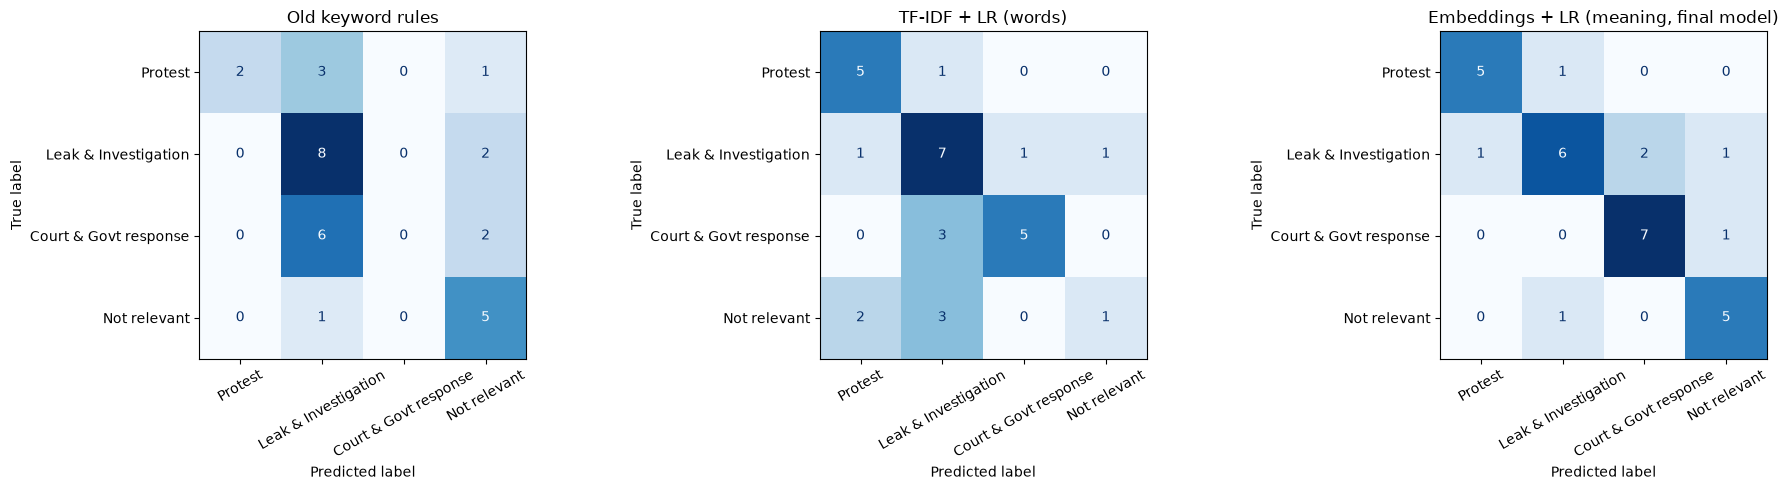

In [15]:
os.makedirs("charts", exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, preds, title in [(axes[0], pred_rules, "Old keyword rules"), (axes[1], pred_model, "TF-IDF + LR (words)"),
                         (axes[2], pred_emb, "Embeddings + LR (meaning, final model)")]:
    ConfusionMatrixDisplay.from_predictions(y_test, preds, labels=LABELS, ax=ax, colorbar=False, cmap="Blues",
                                            xticks_rotation=30)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("charts/confusion_matrix.png", dpi=150)
plt.show()

### Comparing approaches
We compare 6 approaches on **exactly the same data splits**:

| Approach | Idea |
|---|---|
| **Always guess the most common label** | The "dumb" baseline. Any real model must beat this. |
| **Old keyword rules** | The original notebook's method (no learning). |
| **Naive Bayes** | Counts how often each word appears with each label; the classic, very fast text model. |
| **TF-IDF + Logistic Regression** | Learns a weight for every word (used for the word-level "Why?" explanation). |
| **Linear SVM** | Draws the widest possible boundary between labels; often strong on text. |
| **Embeddings + Logistic Regression** | Same classifier, but reads the *meaning* of the headline (final model). |

With only 150 labels, one 30-row test set is noisy, so we use **repeated cross-validation**:
split the data into 5 parts, train on 4 and test on 1, rotate, and repeat with 5 different shuffles = **25 tests per model**.
We report the average macro F1 and its spread (±).

In [16]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import RepeatedStratifiedKFold


def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")


CANDIDATES = {
    "Always guess the most common label": Pipeline([("tfidf", tfidf()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Naive Bayes": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB(alpha=0.1))]),
    "TF-IDF + Logistic Regression": make_model(),
    "Linear SVM": Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(class_weight="balanced"))]),
    "Embeddings + Logistic Regression (final model)": make_embedding_model(),
}

splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42).split(X, y))
rows = []
for name, candidate in CANDIDATES.items():
    f1s, accs, seconds = [], [], 0.0
    for train_idx, test_idx in splits:
        start = time.perf_counter()
        candidate.fit(X.iloc[train_idx], y.iloc[train_idx])
        seconds += time.perf_counter() - start
        pred = candidate.predict(X.iloc[test_idx])
        f1s.append(f1_score(y.iloc[test_idx], pred, average="macro"))
        accs.append(accuracy_score(y.iloc[test_idx], pred))
    rows.append([name, np.mean(f1s), np.std(f1s), np.mean(accs), seconds / len(splits) * 1000])

# The old rules don't learn, but we score them on the same 25 test folds for a fair comparison
f1s = [f1_score(y.iloc[t], rules_predict(X.iloc[t]), average="macro") for _, t in splits]
accs = [accuracy_score(y.iloc[t], rules_predict(X.iloc[t])) for _, t in splits]
rows.append(["Old keyword rules", np.mean(f1s), np.std(f1s), np.mean(accs), 0.0])

comparison = (pd.DataFrame(rows, columns=["Approach", "Macro F1", "± (spread)", "Accuracy", "Training time (ms)"])
              .sort_values("Macro F1", ascending=False).round(2).reset_index(drop=True))
comparison.to_csv("data/model_comparison.csv", index=False)
comparison

,Approach,Macro F1,± (spread),Accuracy,Training time (ms)
0,Embeddings + Logistic Regression (final model),0.74,0.09,0.75,3.64
1,Linear SVM,0.67,0.08,0.68,3.84
2,TF-IDF + Logistic Regression,0.66,0.08,0.67,12.08
3,Naive Bayes,0.65,0.09,0.68,4.25
4,Old keyword rules,0.41,0.07,0.51,0.00
5,Always guess the most common label,0.13,0.00,0.35,3.36


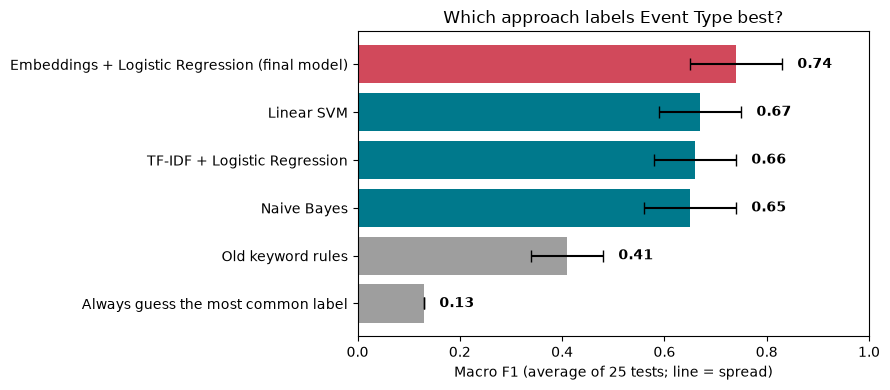

In [17]:
order = comparison.sort_values("Macro F1")
bar_colors = ["#d1495b" if "final model" in a else "#9e9e9e" if a.startswith(("Always", "Old")) else "#00798c"
              for a in order["Approach"]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(order["Approach"], order["Macro F1"], xerr=order["± (spread)"], color=bar_colors, capsize=4)
for i, (v, spread) in enumerate(zip(order["Macro F1"], order["± (spread)"])):
    ax.text(v + spread + 0.03, i, f"{v:.2f}", va="center", fontweight="bold")
ax.set(xlim=(0, 1), xlabel="Macro F1 (average of 25 tests; line = spread)", title="Which approach labels Event Type best?")
plt.tight_layout(); plt.savefig("charts/model_comparison.png", dpi=150); plt.show()

### Learning curve: would more labels help?
We train the model on **24, 48, 72, 96 and 120** labelled articles and test each time on 30 articles it has never seen
(repeated 20 times with different random splits).
- If the line is still **rising** at 120, more labels would very likely make the model better.
- If it has **flattened**, the model has learned all it can from headlines, and more labels would not help much.

In [18]:
from sklearn.model_selection import learning_curve, StratifiedShuffleSplit

curves = []
for model_name, builder in [("TF-IDF + LR (words)", make_model), ("Embeddings + LR (meaning)", make_embedding_model)]:
    sizes, train_scores, test_scores = learning_curve(
        builder(), X, y,
        train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
        cv=StratifiedShuffleSplit(n_splits=20, test_size=30, random_state=42),
        scoring="f1_macro", shuffle=True, random_state=42, error_score=np.nan,
    )
    curves.append(pd.DataFrame({
        "Model": model_name,
        "Labelled articles used for training": sizes,
        "Test macro F1 (mean)": np.nanmean(test_scores, axis=1),
        "± (spread)": np.nanstd(test_scores, axis=1),
        "Training macro F1": np.nanmean(train_scores, axis=1),
    }))
curve = pd.concat(curves, ignore_index=True).round(2)
curve.to_csv("data/learning_curve.csv", index=False)
curve

,Model,Labelled articles used for training,Test macro F1 (mean),± (spread),Training macro F1
0,TF-IDF + LR (words),24,0.45,0.08,1.00
1,TF-IDF + LR (words),48,0.55,0.08,1.00
2,TF-IDF + LR (words),72,0.62,0.08,1.00
3,TF-IDF + LR (words),96,0.64,0.09,1.00
4,TF-IDF + LR (words),120,0.65,0.09,1.00
5,Embeddings + LR (meaning),24,0.56,0.09,1.00
6,Embeddings + LR (meaning),48,0.67,0.08,0.98
7,Embeddings + LR (meaning),72,0.69,0.10,0.95
8,Embeddings + LR (meaning),96,0.71,0.07,0.94
9,Embeddings + LR (meaning),120,0.74,0.09,0.93


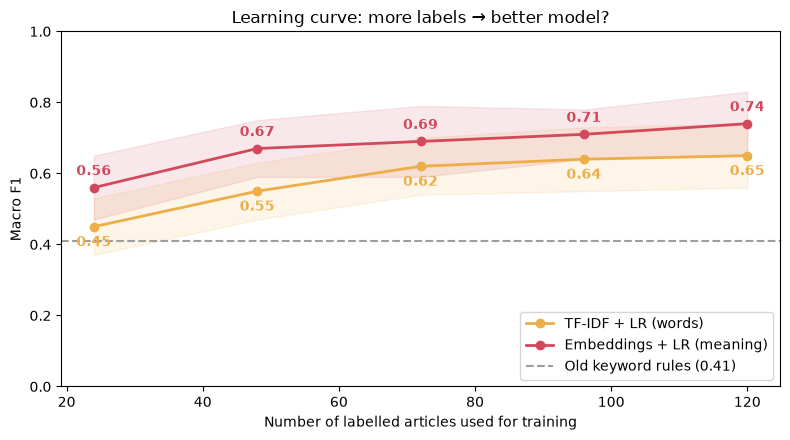

In [19]:
rules_f1 = comparison.set_index("Approach").loc["Old keyword rules", "Macro F1"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for (model_name, part), color, offset in zip(curve.groupby("Model", sort=False), ["#edae49", "#d1495b"], [-14, 9]):
    n, v, s = part["Labelled articles used for training"], part["Test macro F1 (mean)"], part["± (spread)"]
    ax.plot(n, v, "o-", color=color, lw=2, label=model_name)
    ax.fill_between(n, v - s, v + s, color=color, alpha=0.12)
    for xi, yi in zip(n, v):
        ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, offset), ha="center",
                    fontweight="bold", color=color)
ax.axhline(rules_f1, ls="--", color="#9e9e9e", label=f"Old keyword rules ({rules_f1:.2f})")
ax.set(xlabel="Number of labelled articles used for training", ylabel="Macro F1", ylim=(0, 1),
       title="Learning curve: more labels → better model?")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("charts/learning_curve.png", dpi=150); plt.show()

### Error analysis: where does the model go wrong?
To study mistakes fairly, every one of the 150 labelled articles is predicted by a model that **did not see it during training**
(5-fold `cross_val_predict`: each article is predicted by the model trained on the other 4 folds).
Then we look at *which* labels get confused and *why*, using the words that pushed the model towards its wrong answer.

In [20]:
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(make_model(), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                              method="predict_proba")
classes = np.array(sorted(LABELS))                      # predict_proba columns are in sorted label order
oof_pred = classes[oof_proba.argmax(axis=1)]
errors = labels.assign(predicted=oof_pred, confidence=oof_proba.max(axis=1).round(2))
errors = errors[errors["label"] != errors["predicted"]]
print(f"Mistakes: {len(errors)} of {len(labels)} ({len(errors) / len(labels):.0%})")

mix_ups = (errors.groupby(["label", "predicted"]).size().sort_values(ascending=False)
           .rename("Mistakes").reset_index().rename(columns={"label": "True label", "predicted": "Predicted as"}))
mix_ups

Mistakes: 43 of 150 (29%)


,True label,Predicted as,Mistakes
0,Court & Govt response,Leak & Investigation,11
1,Not relevant,Protest,6
2,Not relevant,Leak & Investigation,5
3,Leak & Investigation,Court & Govt response,4
4,Leak & Investigation,Not relevant,4
5,Protest,Leak & Investigation,4
6,Protest,Not relevant,3
7,Not relevant,Court & Govt response,2
8,Protest,Court & Govt response,2
9,Court & Govt response,Not relevant,1


In [21]:
# The words that pushed the model towards its wrong answer (model trained on all labels, for explanation only)
tfidf_step, clf_step = final_model_for_errors = make_model().fit(X, y).named_steps.values()
vocab_all = tfidf_step.get_feature_names_out()


def top_push_words(text, label, k=3):
    vec = tfidf_step.transform([text])
    ids = vec.nonzero()[1]
    if len(ids) == 0:
        return "(no known words)"
    push = vec.data * clf_step.coef_[list(clf_step.classes_).index(label), ids]
    return ", ".join(vocab_all[ids[np.argsort(push)[::-1][:k]]])


errors["Words that misled it"] = [top_push_words(t, p) for t, p in zip(errors["Text"], errors["predicted"])]
error_table = (errors.assign(Headline=errors["Headline"].fillna(errors["Text"].str[:100]))[["Headline", "label", "predicted", "confidence", "Words that misled it"]]
               .rename(columns={"label": "True label", "predicted": "Predicted as", "confidence": "Confidence"})
               .sort_values("Confidence", ascending=False))
error_table.to_csv("data/error_analysis.csv", index=False)
mix_ups.to_csv("data/error_mixups.csv", index=False)
error_table.head(15)

,Headline,True label,Predicted as,Confidence,Words that misled it
126,"Jaish operative, his girlfriend, honeytrap, and a plan to ‘target’ CM Suvendu, CJP pro...",Not relevant,Protest,0.69,"cjp, protest, cjp protest"
83,Uttarakhand university cancels 2 exams after professor leaks question paper,Court & Govt response,Leak & Investigation,0.69,"paper, leaks, exams"
70,7 govt teachers suspended over SSC paper leak in Nizamabad,Court & Govt response,Leak & Investigation,0.63,"paper, paper leak, leak"
54,cockroach janta party scientific dissection of cockroaches,Not relevant,Protest,0.62,"cockroach, party, janta party"
44,"NEET paper leak, Bihar bandh, and the test of democracy",Protest,Leak & Investigation,0.62,"paper, paper leak, leak"
39,CJP reviews progress on judicial reforms agenda,Not relevant,Protest,0.57,"cjp, reviews progress, reviews"
52,Global media writes on man who ‘humbled India’s PM’ & human cost of NEET paper leak,Protest,Leak & Investigation,0.56,"paper, paper leak, leak"
69,CJP stresses swift resolution of tax disputes,Not relevant,Protest,0.52,"cjp, tax disputes, tax"
118,Bihar Teacher Recruitment Exam 2024 Cancelled After Paper Leak Allegations,Court & Govt response,Leak & Investigation,0.50,"paper, paper leak, leak"
149,UPPCS exam cancelled after question paper leak on WhatsApp,Court & Govt response,Leak & Investigation,0.50,"paper, paper leak, leak"


### Which words did the model learn?
The top words for each label: a quick way to check that the model learned sensible things.

In [22]:
final_model = make_model().fit(X, y)          # retrain on all 150 labels (used for word explanations)
joblib.dump(final_model, "models/event_type.joblib")
vocab = np.array(final_model.named_steps["tfidf"].get_feature_names_out())
for label, coefs in zip(final_model.classes_, final_model.named_steps["clf"].coef_):
    print(f"{label:24s}: {', '.join(vocab[np.argsort(coefs)[-10:][::-1]])}")

Court & Govt response   : court, cancelled, anti paper, member, rpsc member, anti, rpsc, exam cancelled, suspended, leak
Leak & Investigation    : paper, paper leak, exam paper, leak, exam, medical, paper leaks, probe, arrest, 2026 paper
Not relevant            : cuet, suicides, cuet ug, 2026, action begin, begin, jee, conducted, ug, data
Protest                 : cjp, dipke, protesters, abhijeet, abhijeet dipke, delhi, movement, protests, students, neet paper


## 5. Label every article and save the final dataset
The **embeddings model** (the most accurate) labels all articles. The TF-IDF model is also saved, because the
dashboard uses it to show *which words* drove a prediction.

In [23]:
final_emb = make_embedding_model().fit(X, y)          # retrain on all 150 labels
joblib.dump({"encoder": EMBEDDING_MODEL, "classifier": final_emb.named_steps["clf"]},
            "models/event_type_embeddings.joblib")
clean["Event Type"] = final_emb.predict(clean["Text"])
clean["Confidence"] = final_emb.predict_proba(clean["Text"]).max(axis=1).round(2)
# Use the human label wherever we have one
human = labels.set_index("row_id")["label"]
clean.loc[human.index, "Event Type"] = human
clean.loc[human.index, "Confidence"] = 1.0

FINAL_COLUMNS = ["Published Date", "Headline", "Outlet", "Event Type", "Confidence", "State", "Organisations",
                 "Name of Exam", "Exam Category", "Board", "Conducted By", "PBT/CBT", "Exam Year", "Link", "Description"]
final = clean[FINAL_COLUMNS]
final.to_csv("data/final_dataset.csv", index=False)
print("Final dataset:", final.shape)
final["Event Type"].value_counts()

Final dataset: (1986, 15)


Event Type
Leak & Investigation     734
Protest                  482
Court & Govt response    392
Not relevant             378
Name: count, dtype: int64

## 6. Analysis
Everything below uses the **relevant** articles only (Event Type ≠ Not relevant).

Relevant articles: 1608 of 1986


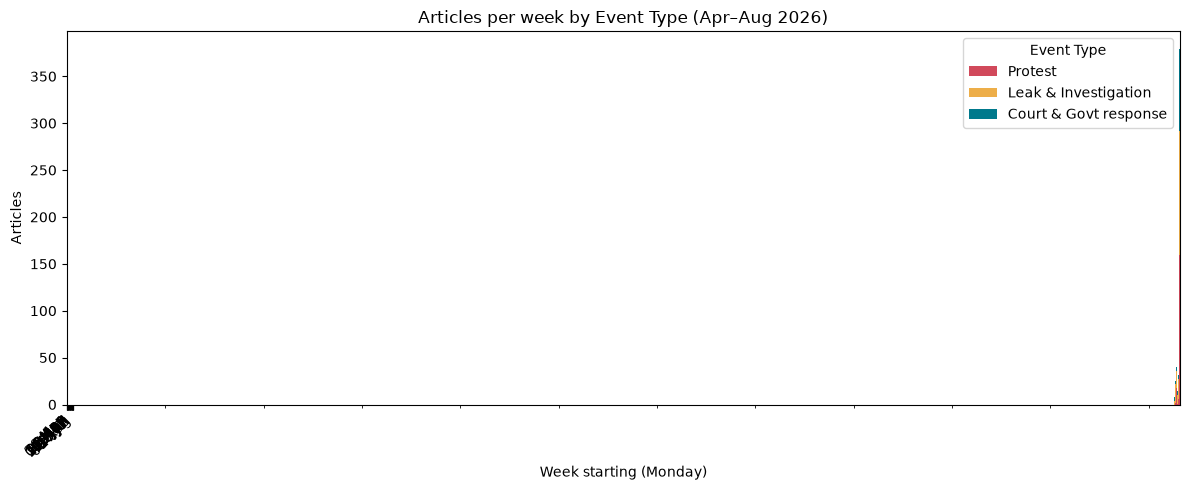

In [24]:
rel = final[final["Event Type"] != "Not relevant"].copy()
COLORS = {"Protest": "#d1495b", "Leak & Investigation": "#edae49", "Court & Govt response": "#00798c"}
print("Relevant articles:", len(rel), "of", len(final))

# Chart 1: the story over time
recent = rel[rel["Published Date"] >= "2026-04-01"]
weekly = (recent.groupby([pd.Grouper(key="Published Date", freq="W-MON", label="left", closed="left"), "Event Type"]).size()
          .unstack(fill_value=0).reindex(columns=list(COLORS), fill_value=0))
ax = weekly.plot(kind="bar", stacked=True, figsize=(12, 5), color=[COLORS[c] for c in weekly.columns], width=0.85)
ax.set_xticks(range(len(weekly)), [d.strftime("%d %b") for d in weekly.index], rotation=45, ha="right")
ax.set(title="Articles per week by Event Type (Apr–Aug 2026)", xlabel="Week starting (Monday)", ylabel="Articles")
# Note: Google News RSS returns the most recent ~100 results per keyword, so the last weeks before the
# data was collected (early Aug 2026) are over-represented. Compare the *mix* of colours, not only the bar height.
plt.tight_layout(); plt.savefig("charts/1_events_over_time.png", dpi=150); plt.show()

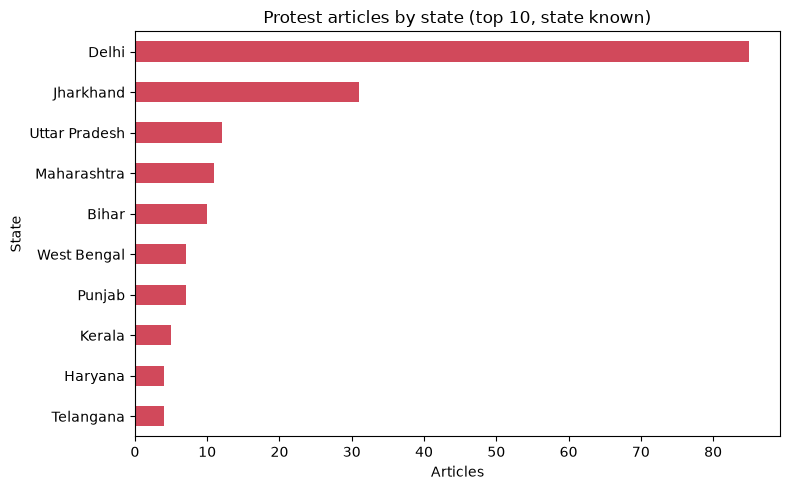

In [25]:
# Chart 2: where the protests were
protest_states = rel.loc[(rel["Event Type"] == "Protest") & (rel["State"] != "Unknown"), "State"].value_counts().head(10)
ax = protest_states.sort_values().plot(kind="barh", color=COLORS["Protest"], figsize=(8, 5))
ax.set(title="Protest articles by state (top 10, state known)", xlabel="Articles")
plt.tight_layout(); plt.savefig("charts/2_protests_by_state.png", dpi=150); plt.show()

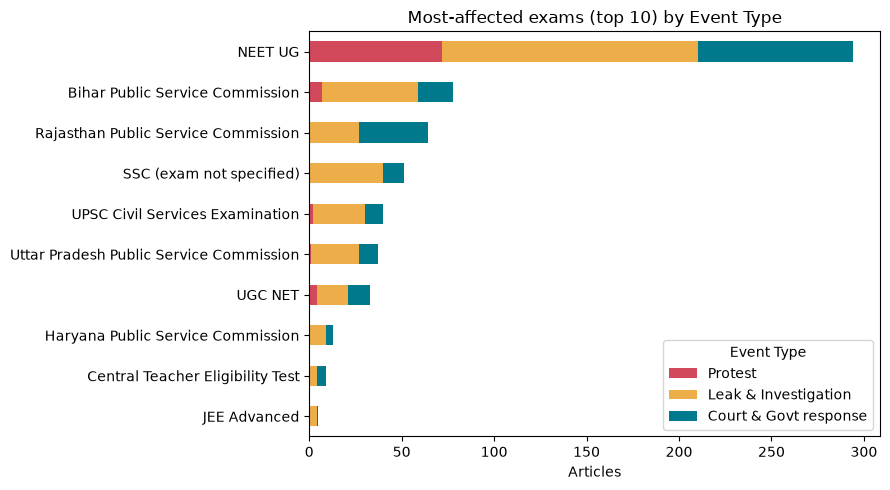

In [26]:
# Chart 3: which exams are in the news, split by event type
top_exams = rel.loc[rel["Name of Exam"] != "Unknown", "Name of Exam"].value_counts().head(10).index
exam_mix = (rel[rel["Name of Exam"].isin(top_exams)].groupby(["Name of Exam", "Event Type"]).size()
            .unstack(fill_value=0).reindex(columns=list(COLORS), fill_value=0))
exam_mix = exam_mix.loc[exam_mix.sum(axis=1).sort_values().index]
ax = exam_mix.plot(kind="barh", stacked=True, color=[COLORS[c] for c in exam_mix.columns], figsize=(9, 5))
ax.set(title="Most-affected exams (top 10) by Event Type", xlabel="Articles", ylabel="")
plt.tight_layout(); plt.savefig("charts/3_exams.png", dpi=150); plt.show()

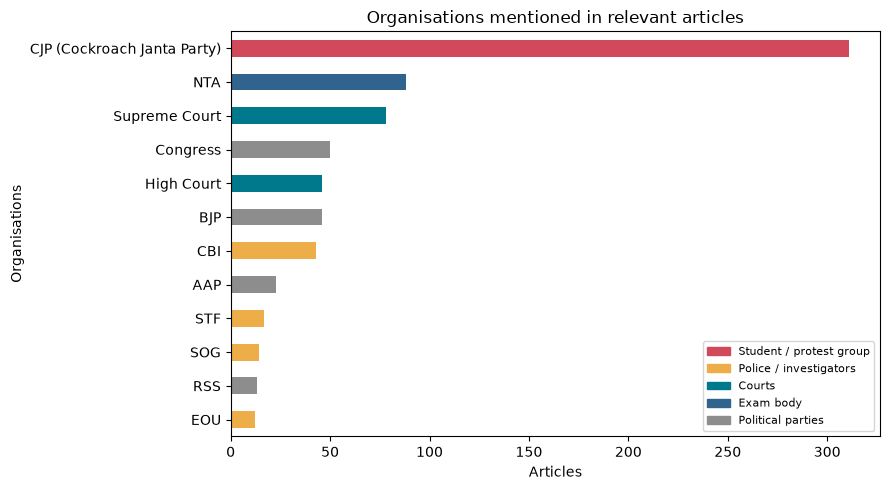

In [27]:
# Chart 4: who is involved
orgs = rel["Organisations"].fillna("").str.split(", ").explode()
orgs = orgs[orgs != ""].value_counts().head(12).sort_values()
GROUP_COLORS = {"Student / protest group": "#d1495b", "Police / investigators": "#edae49", "Courts": "#00798c",
                "Exam body": "#30638e", "Political parties": "#8d8d8d"}
ax = orgs.plot(kind="barh", color=[GROUP_COLORS[ORG_GROUP[o]] for o in orgs.index], figsize=(9, 5))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()], labels=GROUP_COLORS.keys(),
          loc="lower right", fontsize=8)
ax.set(title="Organisations mentioned in relevant articles", xlabel="Articles")
plt.tight_layout(); plt.savefig("charts/4_organisations.png", dpi=150); plt.show()

## 7. Key findings
*(Write these in your own words after looking at the charts.)*

1. …
2. …
3. …
4. …